# 01 · Pricing a European option three ways

**Question:** what is the fair price today of the right to buy a stock at a fixed price one year from now?

This notebook answers it with the closed-form **Black-Scholes** formula, then re-derives the same number with three numerical methods that generalise to harder problems:

| Method | Idea | Why a trading desk uses it |
|---|---|---|
| Monte Carlo | Simulate thousands of futures, average the payoffs | Works for path-dependent and multi-asset payoffs |
| Finite differences (Crank-Nicolson) | Solve the Black-Scholes PDE on a grid | Fast, accurate, gives Greeks for free |
| Binomial tree (CRR) | Let the stock move up/down in discrete steps | Handles **American** early exercise |

Every method is checked against the closed form, and we measure *how fast* each converges.

**Base case used throughout:** spot $S_0 = 100$, strike $K = 100$, expiry $T = 1$ year, risk-free rate $r = 5\%$, volatility $\sigma = 20\%$.

In [1]:
# --- Setup: works both locally and in Google Colab ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
REPO_DIR = "/content/options-pricing-hedging-lab"
if IN_COLAB and not os.path.isdir(REPO_DIR):
    user = input("GitHub username that hosts this repo: ").strip()
    os.system(f"git clone -q https://github.com/{user}/options-pricing-hedging-lab.git {REPO_DIR}")
    if not os.path.isdir(REPO_DIR):
        raise RuntimeError(f"Could not clone github.com/{user}/options-pricing-hedging-lab - check the username and that the repo is public.")
if IN_COLAB:
    os.chdir(f"{REPO_DIR}/notebooks")
sys.path.insert(0, os.path.abspath("../src"))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from optionslab import *
from optionslab.plotting import use_style, save, SERIES, BLUE, ORANGE, AQUA, YELLOW, INK, INK_2, MUTED

use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20

bs_call = float(bs_price(S0, K, T, r, sigma, "call"))
bs_put = float(bs_price(S0, K, T, r, sigma, "put"))
print(f"Black-Scholes call = {bs_call:.4f}")
print(f"Black-Scholes put  = {bs_put:.4f}")

Black-Scholes call = 10.4506
Black-Scholes put  = 5.5735


## 1. What an option pays

A **call** pays $\max(S_T - K, 0)$ at expiry: you only use the right to buy if the stock ends above the strike.
A **put** pays $\max(K - S_T, 0)$. The buyer pays a premium up front, so the profit line is the payoff shifted down by the premium.

The kink at the strike is the whole story: losses are capped at the premium, gains are not. That asymmetry is why options are worth more when the stock is more volatile.

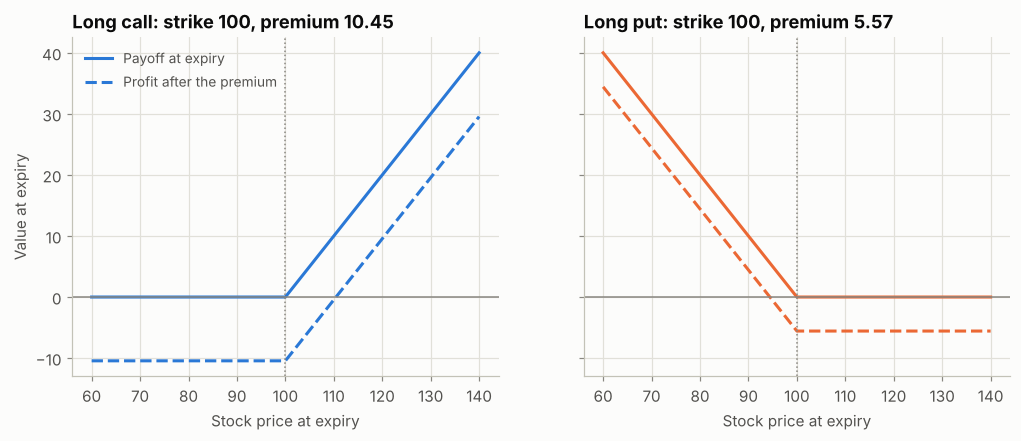

In [3]:
S_T = np.linspace(60, 140, 401)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, opt, prem, color in [(axes[0], "call", bs_call, BLUE), (axes[1], "put", bs_put, ORANGE)]:
    ax.plot(S_T, payoff(S_T, K, opt), color=color, label="Payoff at expiry")
    ax.plot(S_T, payoff(S_T, K, opt) - prem, color=color, ls="--", label="Profit after the premium")
    ax.axhline(0, color=MUTED, lw=1)
    ax.axvline(K, color=MUTED, lw=1, ls=":")
    ax.set_title(f"Long {opt}: strike {K:.0f}, premium {prem:.2f}")
    ax.set_xlabel("Stock price at expiry")
axes[0].set_ylabel("Value at expiry")
axes[0].legend(loc="upper left")
save(fig, "01_payoffs"); plt.show()

## 2. A model for the stock: geometric Brownian motion

We need a model for how the price moves randomly. Black-Scholes assumes **geometric Brownian motion (GBM)**:

$$S_{t+\Delta t} = S_t \exp\!\Big(\big(\mu - \tfrac{1}{2}\sigma^2\big)\Delta t + \sigma\sqrt{\Delta t}\,Z\Big), \qquad Z \sim N(0,1)$$

* We model **percentage** (log) returns, so the price can never go negative.
* $\sigma$ is the annual volatility. Daily moves are independent, so variances add up over time and the typical move over a horizon $t$ grows like $\sigma\sqrt{t}$.
* The $-\tfrac{1}{2}\sigma^2$ term is "volatility drag": +10% then -10% leaves you at 99, not 100. It makes the *average* price grow at exactly $\mu$.

Consequence: $\ln S_T$ is normally distributed, so $S_T$ is **lognormal**: skewed to the right, with a long upper tail.

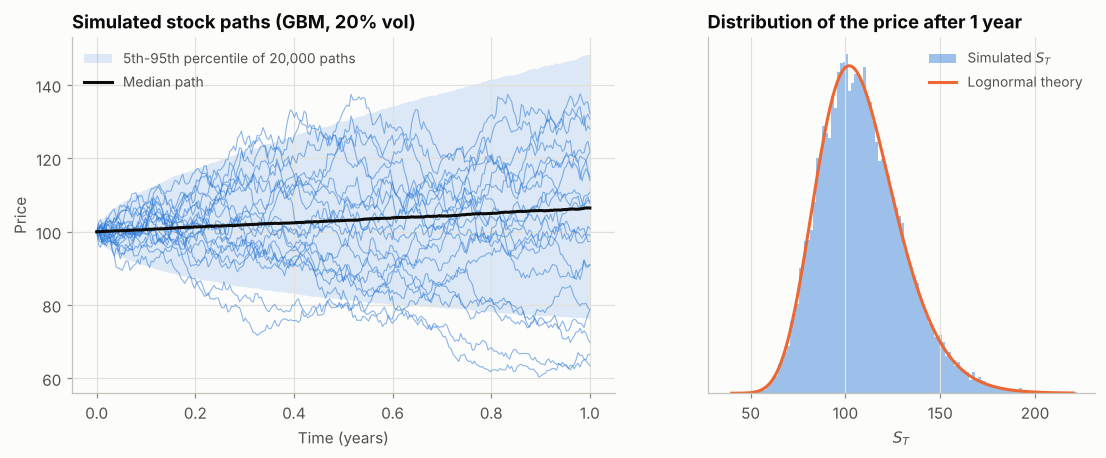

Annualised vol of simulated daily returns: 0.1999  (input 0.20)
Mean of S_T: 108.658  vs theory S0*e^(mu*T) = 108.329


In [4]:
mu_real = 0.08   # real-world drift, only used to draw realistic paths
n_steps = 252    # trading days in a year
paths = simulate_gbm_paths(S0, mu_real, sigma, T, n_steps=n_steps, n_paths=20_000, seed=42)
t_grid = np.linspace(0, T, n_steps + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
lo, hi = np.percentile(paths, [5, 95], axis=0)
ax1.fill_between(t_grid, lo, hi, color=BLUE, alpha=0.15, lw=0, label="5th-95th percentile of 20,000 paths")
ax1.plot(t_grid, paths[:20].T, color=BLUE, lw=0.7, alpha=0.55)
ax1.plot(t_grid, np.median(paths, axis=0), color=INK, lw=2, label="Median path")
ax1.set_title("Simulated stock paths (GBM, 20% vol)")
ax1.set_xlabel("Time (years)"); ax1.set_ylabel("Price")
ax1.legend(loc="upper left")

from scipy.stats import lognorm
m = np.log(S0) + (mu_real - 0.5 * sigma**2) * T
s = sigma * np.sqrt(T)
x = np.linspace(40, 220, 400)
ax2.hist(paths[:, -1], bins=120, density=True, color=BLUE, alpha=0.45, label="Simulated $S_T$")
ax2.plot(x, lognorm.pdf(x, s, scale=np.exp(m)), color=ORANGE, label="Lognormal theory")
ax2.set_title("Distribution of the price after 1 year")
ax2.set_xlabel("$S_T$"); ax2.set_yticks([])
ax2.legend()
save(fig, "02_gbm_paths"); plt.show()

daily = np.diff(np.log(paths), axis=1)
print(f"Annualised vol of simulated daily returns: {daily.std() * np.sqrt(252):.4f}  (input 0.20)")
print(f"Mean of S_T: {paths[:, -1].mean():.3f}  vs theory S0*e^(mu*T) = {S0 * np.exp(mu_real * T):.3f}")

## 3. The Black-Scholes formula

$$C = S_0 N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0 N(-d_1)$$
$$d_1 = \frac{\ln(S_0/K) + (r + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

How to read it:
* $N(d_2)$ is the **risk-neutral probability** that the call finishes in the money, so $K e^{-rT}N(d_2)$ is today's value of paying the strike in those scenarios.
* $N(d_1)$ is the call's **delta**: the number of shares that hedge one call.
* Notice the stock's real drift $\mu$ **does not appear**. Section 4 and notebook 02 explain why.

**Put-call parity** must hold for any model (no-arbitrage): $C - P = S_0 - K e^{-rT}$. A call minus a put with the same strike is the same as owning the stock and owing $K$.

In [5]:
strikes = np.array([80, 90, 100, 110, 120], dtype=float)
calls = bs_price(S0, strikes, T, r, sigma, "call")
puts = bs_price(S0, strikes, T, r, sigma, "put")
from scipy.stats import norm
from optionslab.black_scholes import d1_d2
d1, d2 = d1_d2(S0, strikes, T, r, sigma)

# Check N(d2) really is the probability of finishing in the money under the risk-neutral model
Z = np.random.default_rng(0).standard_normal(1_000_000)
S_T_rn = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
table = pd.DataFrame({
    "strike": strikes,
    "call": calls,
    "put": puts,
    "C - P": calls - puts,
    "S - K e^(-rT)": S0 - strikes * np.exp(-r * T),
    "N(d2)": norm.cdf(d2),
    "simulated P(S_T > K)": [(S_T_rn > k).mean() for k in strikes],
})
table

,strike,call,put,C - P,S - K e^(-rT),N(d2),simulated P(S_T > K)
0,80.0000,24.5888,0.6872,23.9016,23.9016,0.8972,0.8970
1,90.0000,16.6994,2.3101,14.3894,14.3894,0.7507,0.7508
2,100.0000,10.4506,5.5735,4.8771,4.8771,0.5596,0.5600
3,110.0000,6.0401,10.6753,-4.6352,-4.6352,0.3720,0.3726
4,120.0000,3.2475,17.3950,-14.1475,-14.1475,0.2231,0.2240


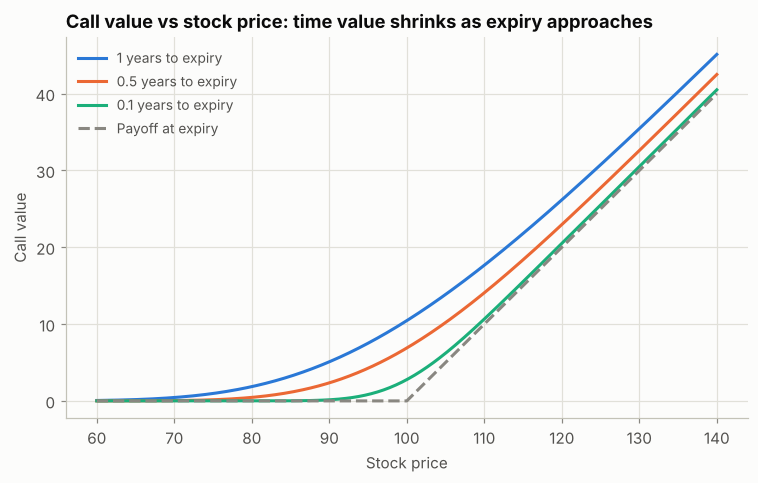

In [6]:
S_axis = np.linspace(60, 140, 401)
fig, ax = plt.subplots(figsize=(8, 4.5))
for T_, color in zip([1.0, 0.5, 0.1], SERIES):
    ax.plot(S_axis, bs_price(S_axis, K, T_, r, sigma, "call"), color=color, label=f"{T_:g} years to expiry")
ax.plot(S_axis, payoff(S_axis, K, "call"), color=MUTED, ls="--", label="Payoff at expiry")
ax.set_title("Call value vs stock price: time value shrinks as expiry approaches")
ax.set_xlabel("Stock price"); ax.set_ylabel("Call value")
ax.legend(loc="upper left")
save(fig, "03_bs_price_curves"); plt.show()

## 4. Monte Carlo pricing

**Risk-neutral pricing:** a trader can hedge an option with the stock (notebook 02 shows this), so its price cannot depend on the stock's expected return. We can therefore price *as if* every asset grows at the risk-free rate $r$:

$$\text{Price} = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}\big[\text{payoff}(S_T)\big], \qquad S_T = S_0 e^{(r - \frac{1}{2}\sigma^2)T + \sigma\sqrt{T}Z}$$

Monte Carlo estimates the expectation with an average over $N$ simulated values of $S_T$. The **standard error** is $\text{std(payoff)}/\sqrt{N}$, so 100× more paths only buys 10× more accuracy. Two classic tricks cut the variance for free:

* **Antithetic variates:** for every draw $Z$ also use $-Z$, so up and down shocks balance exactly in each pair.
* **Control variate:** the discounted stock price $e^{-rT}S_T$ has a known mean ($S_0$). Whatever error the simulation makes on it, it makes a correlated error on the call, so we subtract the predictable part.

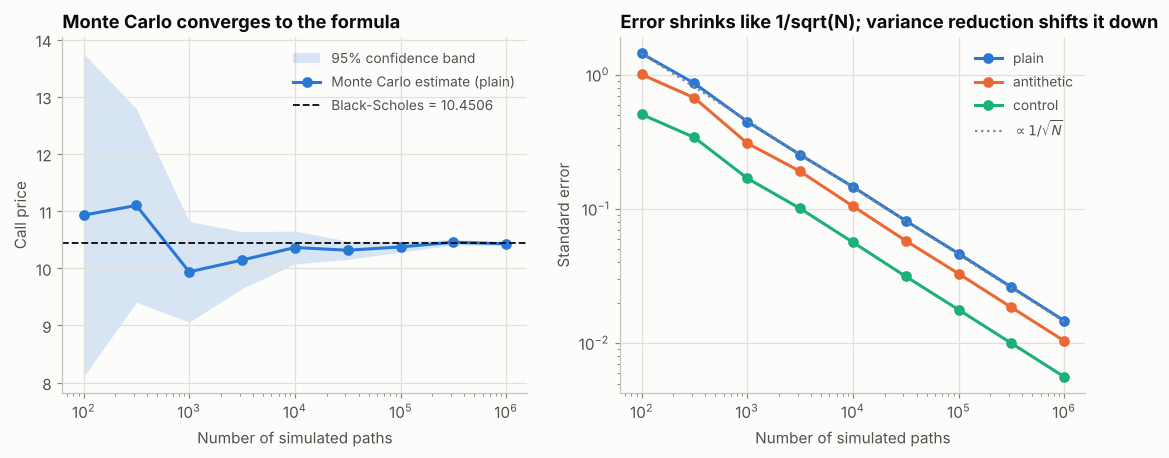

Fitted convergence rate: std_err ~ N^-0.500  (theory: -0.5)
antithetic: variance reduced 2.0x  -> same accuracy with 2.0x fewer paths
   control: variance reduced 6.9x  -> same accuracy with 6.9x fewer paths


In [7]:
Ns = np.unique(np.logspace(2, 6, 9).astype(int))
rows = []
for N in Ns:
    for method in ["plain", "antithetic", "control"]:
        res = mc_european(S0, K, T, r, sigma, "call", n_paths=int(N), method=method, seed=int(N))
        rows.append({"N": int(N), "method": method, "price": res.price, "std_err": res.std_err})
mc = pd.DataFrame(rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
plain = mc[mc.method == "plain"]
ax1.fill_between(plain.N, plain.price - 1.96 * plain.std_err, plain.price + 1.96 * plain.std_err,
                 color=BLUE, alpha=0.18, lw=0, label="95% confidence band")
ax1.plot(plain.N, plain.price, "o-", color=BLUE, label="Monte Carlo estimate (plain)")
ax1.axhline(bs_call, color=INK, lw=1.2, ls="--", label=f"Black-Scholes = {bs_call:.4f}")
ax1.set_xscale("log"); ax1.set_xlabel("Number of simulated paths")
ax1.set_ylabel("Call price"); ax1.set_title("Monte Carlo converges to the formula")
ax1.legend()

for method, color in zip(["plain", "antithetic", "control"], SERIES):
    sub = mc[mc.method == method]
    ax2.loglog(sub.N, sub.std_err, "o-", color=color, label=method)
ref = plain.std_err.iloc[0] * np.sqrt(plain.N.iloc[0] / plain.N)
ax2.loglog(plain.N, ref, color=MUTED, ls=":", lw=1.5, label=r"$\propto 1/\sqrt{N}$")
ax2.set_xlabel("Number of simulated paths"); ax2.set_ylabel("Standard error")
ax2.set_title("Error shrinks like 1/sqrt(N); variance reduction shifts it down")
ax2.legend()
save(fig, "04_mc_convergence"); plt.show()

slope = np.polyfit(np.log(plain.N), np.log(plain.std_err), 1)[0]
last = mc[mc.N == mc.N.max()].set_index("method")
print(f"Fitted convergence rate: std_err ~ N^{slope:.3f}  (theory: -0.5)")
for m in ["antithetic", "control"]:
    vrf = (last.loc["plain", "std_err"] / last.loc[m, "std_err"]) ** 2
    print(f"{m:>10}: variance reduced {vrf:.1f}x  -> same accuracy with {vrf:.1f}x fewer paths")

## 5. Finite differences: solving the Black-Scholes PDE

Hedging arguments show that any option value $V(S,t)$ must satisfy

$$\frac{\partial V}{\partial t} + \tfrac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS\frac{\partial V}{\partial S} - rV = 0.$$

With $x = \ln S$ and $\tau = T - t$ (time remaining) this becomes a **diffusion (heat) equation** with constant coefficients. We start from the payoff at $\tau = 0$ and step forward in $\tau$ on a grid.

* **Crank-Nicolson** averages the explicit and implicit schemes: second-order accurate in both space and time, and stable for any step size. Each step solves one tridiagonal linear system, which costs $O(\text{grid size})$.
* The payoff's kink makes plain Crank-Nicolson ring slightly near the strike, so the first few steps are fully implicit (**Rannacher smoothing**).
* One solve gives the price for *every* spot on the grid, plus delta and gamma from finite differences.

Second-order accuracy means: double the grid resolution, and the error should fall by about 4×.

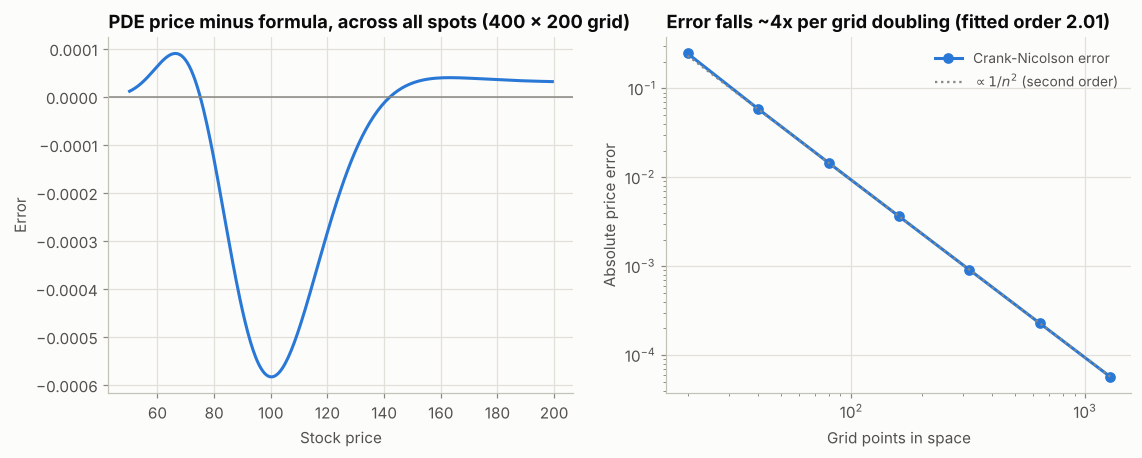

,space steps,time steps,price,abs error,delta error,gamma error,time (ms)
0,20,10,10.2027,0.2479,0.0016,0.0005,1.0821
1,40,20,10.3915,0.0591,0.0004,0.0001,1.0459
2,80,40,10.4359,0.0146,0.0001,0.0000,1.7077
3,160,80,10.4469,0.0036,0.0000,0.0000,3.5011
4,320,160,10.4497,0.0009,0.0000,0.0000,12.2548
5,640,320,10.4504,0.0002,0.0000,0.0000,19.0155
6,1280,640,10.4505,0.0001,0.0000,0.0000,46.6359


In [8]:
rows = []
for n in [20, 40, 80, 160, 320, 640, 1280]:
    t0 = time.perf_counter()
    res = crank_nicolson(S0, K, T, r, sigma, "call", n_space=n, n_time=n // 2)
    ms = (time.perf_counter() - t0) * 1000
    rows.append({"space steps": n, "time steps": n // 2, "price": res.price,
                 "abs error": abs(res.price - bs_call),
                 "delta error": abs(res.delta - float(bs_delta(S0, K, T, r, sigma))),
                 "gamma error": abs(res.gamma - float(bs_gamma(S0, K, T, r, sigma))),
                 "time (ms)": ms})
pde = pd.DataFrame(rows)
order = -np.polyfit(np.log(pde["space steps"]), np.log(pde["abs error"]), 1)[0]

fine = crank_nicolson(S0, K, T, r, sigma, "call", n_space=400, n_time=200)
mask = (fine.S_grid > 50) & (fine.S_grid < 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(fine.S_grid[mask], fine.V_grid[mask] - bs_price(fine.S_grid[mask], K, T, r, sigma), color=BLUE)
ax1.axhline(0, color=MUTED, lw=1)
ax1.set_title("PDE price minus formula, across all spots (400 x 200 grid)")
ax1.set_xlabel("Stock price"); ax1.set_ylabel("Error")

ax2.loglog(pde["space steps"], pde["abs error"], "o-", color=BLUE, label="Crank-Nicolson error")
ref = pde["abs error"].iloc[2] * (pde["space steps"].iloc[2] / pde["space steps"]) ** 2
ax2.loglog(pde["space steps"], ref, color=MUTED, ls=":", lw=1.5, label=r"$\propto 1/n^2$ (second order)")
ax2.set_xlabel("Grid points in space"); ax2.set_ylabel("Absolute price error")
ax2.set_title(f"Error falls ~4x per grid doubling (fitted order {order:.2f})")
ax2.legend()
save(fig, "05_pde_convergence"); plt.show()
pde

## 6. Binomial tree and American options

The Cox-Ross-Rubinstein tree lets the stock move up by $u = e^{\sigma\sqrt{\Delta t}}$ or down by $d = 1/u$ each step. The **risk-neutral probability** of an up-move is

$$p = \frac{e^{r\Delta t} - d}{u - d},$$

the unique probability under which the stock earns exactly the risk-free rate. We fill in payoffs at expiry and walk backwards: each node's value is the discounted, probability-weighted average of its two children.

**American options** can be exercised at any time. In the tree that is one extra line: at every node take $\max(\text{continuation value}, \text{exercise now})$. There is no closed-form formula for an American put, which is why trees and PDEs matter.

Two facts worth knowing for interviews:
* An American **call** on a non-dividend stock is never exercised early, so it equals the European call.
* An American **put** *can* be worth exercising early: once deep in the money, getting $K$ now and earning interest on it beats waiting.

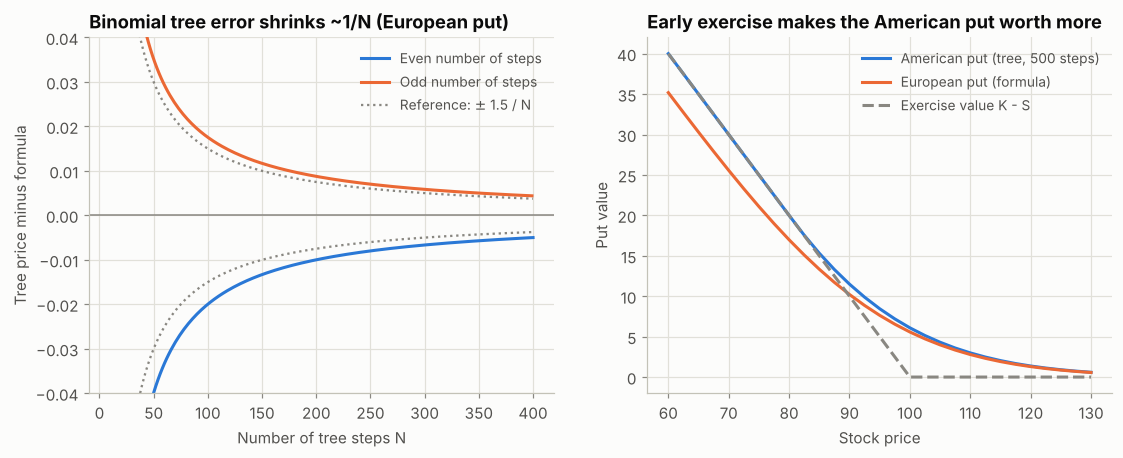

At S = 100: American put 6.0900 vs European put 5.5735 -> early-exercise premium 0.5165
American call 10.4496 vs European call on the same tree 10.4496 (identical: never optimal to exercise a call early without dividends)


In [9]:
steps = np.arange(10, 401)
euro_put = np.array([crr_price(S0, K, T, r, sigma, "put", n_steps=n) for n in steps])

spots = np.linspace(60, 130, 29)
amer = np.array([crr_price(s, K, T, r, sigma, "put", n_steps=500, american=True) for s in spots])
euro = bs_price(spots, K, T, r, sigma, "put")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
even = steps % 2 == 0
ax1.plot(steps[even], (euro_put - bs_put)[even], color=BLUE, label="Even number of steps")
ax1.plot(steps[~even], (euro_put - bs_put)[~even], color=ORANGE, label="Odd number of steps")
ax1.plot(steps, 1.5 / steps, color=MUTED, ls=":", lw=1.5, label=r"Reference: $\pm$ 1.5 / N")
ax1.plot(steps, -1.5 / steps, color=MUTED, ls=":", lw=1.5)
ax1.axhline(0, color=MUTED, lw=1)
ax1.set_ylim(-0.04, 0.04)
ax1.set_title("Binomial tree error shrinks ~1/N (European put)")
ax1.set_xlabel("Number of tree steps N"); ax1.set_ylabel("Tree price minus formula")
ax1.legend()

ax2.plot(spots, amer, color=BLUE, label="American put (tree, 500 steps)")
ax2.plot(spots, euro, color=ORANGE, label="European put (formula)")
ax2.plot(spots, np.maximum(K - spots, 0), color=MUTED, ls="--", label="Exercise value K - S")
ax2.set_title("Early exercise makes the American put worth more")
ax2.set_xlabel("Stock price"); ax2.set_ylabel("Put value")
ax2.legend()
save(fig, "06_binomial_american"); plt.show()

amer_atm = crr_price(S0, K, T, r, sigma, "put", n_steps=2000, american=True)
amer_call = crr_price(S0, K, T, r, sigma, "call", n_steps=2000, american=True)
print(f"At S = 100: American put {amer_atm:.4f} vs European put {bs_put:.4f} -> early-exercise premium {amer_atm - bs_put:.4f}")
euro_call_tree = crr_price(S0, K, T, r, sigma, "call", n_steps=2000)
print(f"American call {amer_call:.4f} vs European call on the same tree {euro_call_tree:.4f} "
      "(identical: never optimal to exercise a call early without dividends)")

## 7. Head-to-head comparison

In [10]:
def timed(fn, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); value = fn(); best = min(best, time.perf_counter() - t0)
    return value, best * 1000

mc_plain = lambda: mc_european(S0, K, T, r, sigma, n_paths=1_000_000, seed=7)
mc_cv = lambda: mc_european(S0, K, T, r, sigma, n_paths=1_000_000, method="control", seed=7)
entries = [
    ("Black-Scholes formula", lambda: float(bs_price(S0, K, T, r, sigma)), "Closed form; simple European payoffs only"),
    ("Monte Carlo, 1M paths (plain)", mc_plain, "Any payoff: path-dependent, many assets"),
    ("Monte Carlo, 1M paths (control variate)", mc_cv, "Same, with a smaller standard error"),
    ("Crank-Nicolson PDE, 400 x 200 grid", lambda: crank_nicolson(S0, K, T, r, sigma, n_space=400, n_time=200).price, "Whole price curve and Greeks in one solve"),
    ("CRR binomial tree, 1,000 steps", lambda: crr_price(S0, K, T, r, sigma, n_steps=1000), "Simple; handles American exercise"),
]
rows = []
for name, fn, note in entries:
    value, ms = timed(fn)
    std_err = value.std_err if hasattr(value, "std_err") else np.nan   # only Monte Carlo has sampling error
    value = value.price if hasattr(value, "price") else value
    rows.append({"method": name, "call price": value, "abs error": abs(value - bs_call),
                 "MC std error": std_err, "time (ms)": ms, "best for": note})
comparison = pd.DataFrame(rows).set_index("method")
comparison

,call price,abs error,MC std error,time (ms),best for
method,,,,,
Black-Scholes formula,10.4506,0.0000,NaN,0.2155,Closed form; simple European payoffs only
"Monte Carlo, 1M paths (plain)",10.4452,0.0054,0.0147,25.8595,"Any payoff: path-dependent, many assets"
"Monte Carlo, 1M paths (control variate)",10.4475,0.0031,0.0056,40.3456,"Same, with a smaller standard error"
"Crank-Nicolson PDE, 400 x 200 grid",10.4500,0.0006,NaN,9.7803,Whole price curve and Greeks in one solve
"CRR binomial tree, 1,000 steps",10.4486,0.0020,NaN,3.5396,Simple; handles American exercise


## 8. The Greeks: how the price reacts

| Greek | Definition | Meaning for a trader |
|---|---|---|
| Delta $\Delta$ | $\partial V/\partial S$ | Shares needed to hedge one option |
| Gamma $\Gamma$ | $\partial^2 V/\partial S^2$ | How fast delta changes: how often you must re-hedge |
| Vega | $\partial V/\partial \sigma$ | P&L per unit change in volatility |
| Theta $\Theta$ | $\partial V/\partial t$ | Value lost per day just from time passing |

Gamma and vega are largest **at the money** and **close to expiry** (gamma) or **far from expiry** (vega). Long options have positive gamma and negative theta: you pay time decay to own convexity. Notebook 02 turns this into a P&L equation.

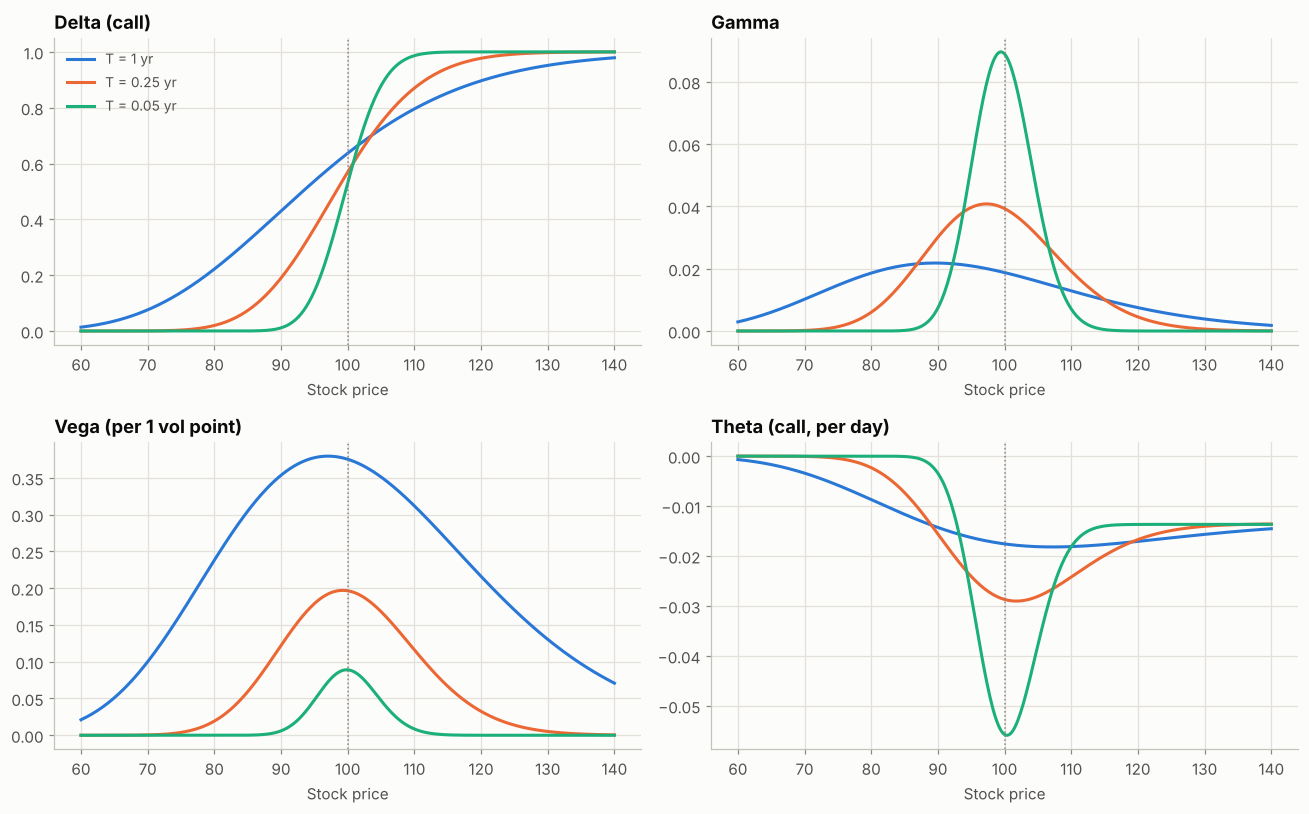

In [11]:
S_axis = np.linspace(60, 140, 401)
expiries = [1.0, 0.25, 0.05]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
panels = [
    ("Delta (call)", lambda T_: bs_delta(S_axis, K, T_, r, sigma, "call")),
    ("Gamma", lambda T_: bs_gamma(S_axis, K, T_, r, sigma)),
    ("Vega (per 1 vol point)", lambda T_: bs_vega(S_axis, K, T_, r, sigma) / 100),
    ("Theta (call, per day)", lambda T_: bs_theta(S_axis, K, T_, r, sigma, "call") / 365),
]
for ax, (title, fn) in zip(axes.ravel(), panels):
    for T_, color in zip(expiries, SERIES):
        ax.plot(S_axis, fn(T_), color=color, label=f"T = {T_:g} yr")
    ax.axvline(K, color=MUTED, lw=1, ls=":")
    ax.set_title(title); ax.set_xlabel("Stock price")
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
save(fig, "07_greeks"); plt.show()

**Sanity check:** each analytic Greek should match a "bump and reprice" finite difference.

In [12]:
h = 1e-3
price = lambda S=S0, T_=T, r_=r, vol=sigma: float(bs_price(S, K, T_, r_, vol, "call"))
checks = pd.DataFrame({
    "analytic": {
        "delta": float(bs_delta(S0, K, T, r, sigma)),
        "gamma": float(bs_gamma(S0, K, T, r, sigma)),
        "vega": float(bs_vega(S0, K, T, r, sigma)),
        "theta": float(bs_theta(S0, K, T, r, sigma)),
        "rho": float(bs_rho(S0, K, T, r, sigma)),
    },
    "bump and reprice": {
        "delta": (price(S=S0 + h) - price(S=S0 - h)) / (2 * h),
        "gamma": (price(S=S0 + h) - 2 * price() + price(S=S0 - h)) / h**2,
        "vega": (price(vol=sigma + h) - price(vol=sigma - h)) / (2 * h),
        "theta": -(price(T_=T + h) - price(T_=T - h)) / (2 * h),
        "rho": (price(r_=r + h) - price(r_=r - h)) / (2 * h),
    },
})
checks["difference"] = checks["analytic"] - checks["bump and reprice"]
checks

,analytic,bump and reprice,difference
delta,0.6368,0.6368,0.0000
gamma,0.0188,0.0188,0.0000
vega,37.5240,37.5240,0.0000
theta,-6.4140,-6.4140,0.0000
rho,53.2325,53.2324,0.0001


## Takeaways

1. **Four independent methods agree** with the Black-Scholes formula to 3-4 decimal places, which is strong evidence the implementation is right.
2. **Monte Carlo error falls like $1/\sqrt{N}$.** Variance reduction (antithetic, control variates) is the cheapest way to more accuracy.
3. **Crank-Nicolson is second-order:** doubling the grid cuts the error ~4×, and one solve prices every spot at once.
4. **Trees handle early exercise.** The American put is worth more than the European one; the American call (no dividends) is not.
5. The real drift $\mu$ never enters the price. **Notebook 02** shows *why*: the option can be replicated by trading the stock.